In [1]:
"""
Kerr-comb model: normalised Lugiato-Lefever equation (LLE) with a laser scan.

The LLE is solved with a symmetric split-step scheme on the azimuthal grid:

    d psi / d tau = -(1 + i*zeta) psi - i*d2*d^2psi/dtheta^2 + i|psi|^2 psi + f

Detuning is swept from blue to red across resonance, which is how a real device
is brought into the soliton regime, and the final state is then held fixed so a
*steady* state - not a scan transient - is reported.

Scope / honesty notes
---------------------
* The model is dimensionless.  The detuning scan is fast (about 0.057 zeta per
  normalised time unit) and the scan stops just below the adiabatic soliton
  threshold zeta = pi^2 f^2 / 8 for the *normalised* LLE, where the dispersion
  coefficient is unity.  Here the dispersion term carries an explicit d2, so the
  effective detuning scale differs by ~1/d2 and the threshold line on the plot is
  only indicative.  The state at the end of the scan is therefore classified
  explicitly rather than assumed to be a single soliton.
* The measured per-line powers are exported for the link cells as a *relative*
  profile in dB.  Turning that into absolute dBm needs the device parameters
  (FSR, Q, coupling, pump power, Kerr nonlinearity and effective mode area),
  which are not fixed here, so no absolute calibration is claimed.
"""

import numpy as np
import matplotlib.pyplot as plt


class MicrocombSim:
    def __init__(self, N=512, d2=0.02, f2=4.0, dtau=0.002):
        """
        Parameters:
        -----------
        N    : int, number of azimuthal modes (grid points)
        d2   : float, normalized GVD (d2 > 0: anomalous)
        f2   : float, normalized pump power f^2
        dtau : float, time step per split-step iteration
        """
        self.N = N
        self.d2 = d2
        self.f = np.sqrt(f2)
        self.dtau = dtau

        # Spatial grid
        self.theta = np.linspace(-np.pi, np.pi, N, endpoint=False)
        # Mode numbers: mu = [0, 1, ..., N/2-1, -N/2, ..., -1]
        self.mu = np.fft.fftfreq(N, d=1.0 / N)

        # Intracavity field
        self.psi = np.zeros(N, dtype=np.complex128)
        self.add_vacuum_noise()

    def add_vacuum_noise(self, noise_level=1e-3):
        """Add low-level white noise to seed MI/soliton formation."""
        noise = (np.random.randn(self.N) + 1j * np.random.randn(self.N)) / np.sqrt(2)
        self.psi += noise_level * noise

    def step(self, zeta):
        """
        Single symmetric split-step iteration:
        1. Half-step Nonlinear Kerr rotation: dpsi/dtau = i|psi|^2 psi
        2. Full-step Linear dispersion + detuning + pump:
           dpsi/dtau = -(1 + i*zeta - i*d2*mu^2) psi + f
        3. Half-step Nonlinear Kerr rotation
        """
        dt = self.dtau

        # 1. Half-step Kerr
        self.psi *= np.exp(1j * np.abs(self.psi) ** 2 * (dt / 2.0))

        # 2. Linear step in Fourier domain
        # L_mu = -(1 + i*zeta) - i*d2*mu^2
        # d psi_mu / dtau = L_mu * psi_mu + f * delta(mu)
        L = -(1.0 + 1j * zeta) - 1j * self.d2 * (self.mu ** 2)

        psi_k = np.fft.fft(self.psi)

        # Exact integration of y' = L*y + F -> y(t+dt) = y(t)*e^(L*dt) + F*(e^(L*dt)-1)/L
        exp_L = np.exp(L * dt)
        psi_k = psi_k * exp_L

        # Drive pump on mode mu = 0 (FFT index 0)
        pump_k = self.f * self.N
        L0 = L[0]
        phi_term = (exp_L[0] - 1.0) / L0
        psi_k[0] += pump_k * phi_term

        self.psi = np.fft.ifft(psi_k)

        # 3. Half-step Kerr
        self.psi *= np.exp(1j * np.abs(self.psi) ** 2 * (dt / 2.0))

    def run(self, zeta, total_tau):
        """Run for a duration of total_tau at constant detuning zeta."""
        n_steps = int(total_tau / self.dtau)
        for _ in range(n_steps):
            self.step(zeta)

    def scan_laser(self, zeta_start=-2.0, zeta_end=5.0, total_tau=150.0, save_every=50):
        """
        Scan detuning zeta from blue to red across resonance.
        Returns history of detuning, average power, and space-time waterfall.
        """
        n_steps = int(total_tau / self.dtau)
        zeta_array = np.linspace(zeta_start, zeta_end, n_steps)

        history_zeta = []
        history_mean_power = []
        waterfall = []

        for step_idx, zeta in enumerate(zeta_array):
            self.step(zeta)
            if step_idx % save_every == 0:
                p_int = np.abs(self.psi) ** 2
                history_zeta.append(zeta)
                history_mean_power.append(np.mean(p_int))
                waterfall.append(p_int.copy())

        return np.array(history_zeta), np.array(history_mean_power), np.array(waterfall)

    def count_localised(self, level=0.5):
        """Number of localised features (solitons) in |psi(theta)|^2."""
        p = np.abs(self.psi) ** 2
        if p.max() <= 0.0:
            return 0
        above = p > level * p.max()
        return int(np.sum(above & ~np.roll(above, 1)))

    def classify(self, level=0.5):
        """Describe the intracavity state, so it is never silently assumed."""
        n = self.count_localised(level)
        if n == 0:
            return "homogeneous CW (no localisation)"
        if n == 1:
            return "single soliton"
        return f"{n}-soliton crystal"

    def line_power_db(self, max_mode=32):
        """Measured per-line power, in dB relative to the strongest comb line.

        The pump line (mu = 0) is excluded: it carries the pump, not data, and a
        real transmitter filters it out.  Returns ``(modes, power_db, pump_frac)``
        where ``pump_frac`` is the fraction of the intracavity power still sitting
        in the pump line.
        """
        spec = np.abs(np.fft.fft(self.psi) / self.N) ** 2
        pump_frac = float(spec[0] / spec.sum())
        keep = (self.mu != 0) & (np.abs(self.mu) <= max_mode)
        modes = self.mu[keep].astype(np.int64)
        power = spec[keep]
        order = np.argsort(modes)
        return modes[order], 10.0 * np.log10(np.maximum(power[order] / power.max(), 1e-30)), pump_frac


# ==========================================
# Example 1: Laser Scan (Soliton Formation)
# ==========================================
if __name__ == "__main__":
    np.random.seed(5)          # reproducible vacuum seed / scan
    sim = MicrocombSim(N=512, d2=0.02, f2=4.0, dtau=0.002)

    print("Running laser scan across resonance...")
    zetas, mean_powers, waterfall = sim.scan_laser(
        zeta_start=-2.0,
        zeta_end=4.8,
        total_tau=120.0,
        save_every=50
    )

    # Calculate final comb spectrum in dB
    comb_spectrum = np.abs(np.fft.fft(sim.psi) / sim.N) ** 2
    comb_spectrum_dB = 10 * np.log10(np.maximum(comb_spectrum, 1e-12))
    mu_shifted = np.fft.fftshift(sim.mu)
    spec_shifted = np.fft.fftshift(comb_spectrum_dB)

    # Plot results
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    # 1. Intracavity Profile |psi(theta)|^2
    axs[0, 0].plot(sim.theta, np.abs(sim.psi) ** 2, color='darkblue')
    axs[0, 0].set_title("Intracavity Profile |psi(theta)|^2 (end of scan)")
    axs[0, 0].set_xlabel("theta (rad)")
    axs[0, 0].set_ylabel("Power |psi|^2")
    axs[0, 0].set_xlim(-np.pi, np.pi)
    axs[0, 0].grid(True, alpha=0.3)

    # 2. Optical Frequency Comb Spectrum (dB)
    axs[0, 1].plot(mu_shifted, spec_shifted, color='crimson')
    axs[0, 1].set_title("Comb Spectrum (dB vs mu)")
    axs[0, 1].set_xlabel("Relative Mode Number mu")
    axs[0, 1].set_ylabel("Power (dB)")
    axs[0, 1].set_xlim(-sim.N // 4, sim.N // 4)
    axs[0, 1].set_ylim(-60, 10)
    axs[0, 1].grid(True, alpha=0.3)

    # 3. Space-Time Waterfall
    extent = [-np.pi, np.pi, zetas[-1], zetas[0]]
    im = axs[1, 0].imshow(waterfall, aspect='auto', extent=extent, cmap='magma')
    axs[1, 0].set_title("Space-Time / Detuning Evolution")
    axs[1, 0].set_xlabel("theta (rad)")
    axs[1, 0].set_ylabel("Detuning zeta")
    fig.colorbar(im, ax=axs[1, 0], label="|psi|^2")

    # 4. Bistability / Intracavity Power vs Detuning
    axs[1, 1].plot(zetas, mean_powers, color='purple', label="Laser Scan")

    # Analytical CW bistability: f^2 = rho (1 + (zeta - rho)^2)
    # rho starts above zero so that f^2 / rho stays finite
    rho_cw = np.linspace(0.02, 4.5, 500)
    zeta_cw = rho_cw + np.sqrt(np.maximum(0, sim.f ** 2 / rho_cw - 1))
    axs[1, 1].plot(zeta_cw, rho_cw, 'k--', alpha=0.4, label="CW Upper Branch")
    zeta_cw_low = rho_cw - np.sqrt(np.maximum(0, sim.f ** 2 / rho_cw - 1))
    axs[1, 1].plot(zeta_cw_low, rho_cw, 'k--', alpha=0.4, label="CW Lower Branch")
    axs[1, 1].axvline(np.pi ** 2 * sim.f ** 2 / 8.0, color='r', linestyle=':',
                      label=r"$\zeta_{max} = \pi^2 f^2 / 8$ (normalised-LLE estimate)")

    axs[1, 1].set_title(r"Intracavity Power $\langle|\psi|^2\rangle$ vs Detuning $\zeta$")
    axs[1, 1].set_xlabel("Detuning zeta")
    axs[1, 1].set_ylabel(r"$\langle|\psi|^2\rangle$")
    axs[1, 1].set_ylim(0, 3)
    axs[1, 1].grid(True, alpha=0.3)
    axs[1, 1].legend(loc='upper left', fontsize=8)

    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------
    # STEADY STATE AND COMB LINE POWERS FOR THE LINK CELLS
    # ------------------------------------------------------------------
    # The scan is a transient; hold the final detuning so the reported state is
    # a steady state, then classify it instead of assuming a single soliton.
    ZETA_HOLD = float(zetas[-1])
    HOLD_TAU = 100.0
    sim.run(ZETA_HOLD, HOLD_TAU)

    comb_state = sim.classify()
    comb_n_solitons = sim.count_localised()
    comb_mode_index, comb_line_power_db, comb_pump_fraction = sim.line_power_db(max_mode=32)

    # A line is worth hopping to only if its OSNR still clears the FEC threshold;
    # the link cell decides that from this profile (see OSNR_THRESHOLD_DB there).
    USABLE_BUDGET_DB = 6.0
    n_usable = int(np.sum(comb_line_power_db >= -USABLE_BUDGET_DB))

    print()
    print(f"Steady state at zeta = {ZETA_HOLD:.2f} ({HOLD_TAU:.0f} normalised time units held)")
    print(f"State classified     : {comb_state}")
    print(f"Pump line (mu = 0)   : {100*comb_pump_fraction:.1f}% of the intracavity power")
    print(f"Comb lines exported  : {len(comb_mode_index)} modes (|mu| <= 32, pump excluded)")
    print(f"Strongest comb line  : mode {comb_mode_index[np.argmax(comb_line_power_db)]}")
    print(f"Envelope spread      : {comb_line_power_db.min():.1f} dB across the exported modes")
    print(f"Lines within {USABLE_BUDGET_DB:.0f} dB    : {n_usable} -> that is what the hop layer can use")
    print("Note: relative dB only.  Absolute dBm per line needs the device parameters")
    print("      (FSR, Q, coupling, pump power, gamma, A_eff), which are not set here.")


ModuleNotFoundError: No module named 'numpy'

In [ ]:
"""
Physical-layer security link for a Kerr-comb QAM-16 transmission.

Subsystems
----------
1. HybridKeyEngine   - expands a shared root secret into purpose-bound sub-keys.
2. Keyed scrambler   - a SHAKE-256 keystream drives the permutation, the
                       amplitude/phase mask and a per-block keyed pilot, and is
                       bound to a per-frame nonce.
3. Optical channel   - unknown carrier frequency offset, Wiener phase noise, ASE
                       and an optional loss-of-signal burst.
4. Receiver DSP      - de-scramble -> blind coarse CFO acquisition -> carrier
                       phase recovery -> pilot-based quadrant resolution ->
                       de-interleave, with re-acquisition after a loss of lock.

Why the order matters
---------------------
The mask is applied per symbol in the time domain, so it can be inverted *before*
the frequency offset is known.  That is what makes a blind CFO estimator possible
at all: before de-scrambling the mask phase is uniform, the constellation is
circularly symmetric and no exploitable spectral line exists; afterwards the
signal is a plain rotated QAM-16 and the classical 4th-power line reappears.

Why the pilot is needed
-----------------------
Blind phase search on QAM-16 has an inherent 90 degree quadrant ambiguity (the
grid maps onto itself).  Starting from a known sample the ambiguity is harmless,
but a receiver that re-acquires mid-frame has no phase reference, so each block
carries a short *keyed* pilot that resolves the quadrant.  Because the pilot is
derived from the keystream it is useless to an eavesdropper as known plaintext.

Security notes
--------------
* The keystream is a CSPRNG (SHAKE-256) keyed by the full 32-byte sub-key and a
  per-frame nonce, so mask entropy equals key entropy and the mask is never
  reused.  Seeding a PCG64 from four key bytes gave 32 bits of entropy and
  repeated the same mask in every frame.
* Phase tracking must precede de-interleaving: the CFO is a ramp in time and the
  permutation would scramble that ramp.

Scope
-----
Reference channel: AWGN, Wiener phase noise, unknown CFO, emulated outage.  There
is no fibre here - no attenuation, chromatic dispersion, polarisation effects,
Kerr nonlinearity, amplifier ASE accumulation or converter bandwidth limits.
"""

import hashlib
import hmac
import numpy as np

SYMBOL_RATE_HZ = 32e9
SCRAMBLE_MIN_AMP = 0.6
SCRAMBLE_MAX_AMP = 1.4
PILOT_LEN = 32                     # keyed reference symbols per block (= 1 CPR sub-block)
QAM16_LEVELS = np.array([-3.0, -1.0, 1.0, 3.0]) / np.sqrt(10.0)
QAM16_IDEAL = (QAM16_LEVELS[:, None] + 1j * QAM16_LEVELS[None, :]).ravel()
QAM16_PEAK_POWER = float(np.max(np.abs(QAM16_IDEAL) ** 2))
SD_FEC_BER = 2e-2                  # stated SD-FEC threshold, pre-FEC BER
REF_BW_HZ = 12.5e9                 # 0.1 nm at 1550 nm
TRACK_RANGE_HZ = 0.25 / (2 * np.pi * 32) * SYMBOL_RATE_HZ


# ----------------------------------------------------------------------
# 1. SUBSYSTEM 3: HYBRID KEY ENGINE
# ----------------------------------------------------------------------
class HybridKeyEngine:
    """Derive independent 256-bit sub-keys from a shared root secret."""

    def __init__(self, shared_root_secret: bytes):
        """Store the root secret (for example from QKD or a PUF)."""
        self.master_secret = bytes(shared_root_secret)

    def derive_key(self, context_label: str) -> bytes:
        """Derive a 32-byte sub-key bound to a context label."""
        return hmac.new(self.master_secret, context_label.encode('utf-8'),
                        hashlib.sha256).digest()


# ----------------------------------------------------------------------
# 2. SUBSYSTEM 2: TRANSMITTER DSP (keystream + keyed pre-distortion)
# ----------------------------------------------------------------------
def keystream_uniforms(key, frame_id, block_id, count, label=b"PD"):
    """Return ``count`` doubles in [0, 1) from SHAKE-256(key, label, frame, block).

    The full key enters the hash, so mask entropy is key entropy (256 bits)
    instead of the 32 bits a truncated integer seed gives.  The frame id keeps
    the mask fresh for every frame; without it the mask repeats and one frame
    unmasks the next.

    Parameters
    ----------
    key : bytes
        Sub-key from :class:`HybridKeyEngine`.
    frame_id, block_id : int
        Non-secret counters that both link ends step through identically.
    count : int
        Number of uniform values required.
    label : bytes
        Domain separation, so one key can feed several keystreams.

    Returns
    -------
    ndarray
        53-bit-precision uniforms in [0, 1).
    """
    h = hashlib.shake_256()
    h.update(key)
    h.update(label)
    h.update(int(frame_id).to_bytes(8, 'big'))
    h.update(int(block_id).to_bytes(8, 'big'))
    raw = np.frombuffer(h.digest(8 * count), dtype='>u8')
    return (raw >> np.uint64(11)).astype(np.float64) * (2.0 ** -53)


def scramble_plan(key, frame_id, block_id, block_size, scramble_amplitude=True):
    """Return the (permutation, amplitude, phase, pilot) mask for one block.

    Both link ends derive this from the same key and counters, so nothing is
    transmitted.  The permutation comes from sorting uniform values, which is
    uniform over the block and needs no Fisher-Yates loop.  The pilot is a keyed
    QAM-16 sequence rather than a fixed public one, so an eavesdropper cannot use
    it as known plaintext.
    """
    u = keystream_uniforms(key, frame_id, block_id, 3 * block_size + PILOT_LEN)
    perm = np.argsort(u[:block_size], kind='stable')
    amp = SCRAMBLE_MIN_AMP + (SCRAMBLE_MAX_AMP - SCRAMBLE_MIN_AMP) * u[block_size:2 * block_size]
    if not scramble_amplitude:      # reference mode: phase-only scrambling
        amp = np.ones(block_size)
    phase = 2.0 * np.pi * u[2 * block_size:3 * block_size]
    pilot = QAM16_IDEAL[np.floor(u[3 * block_size:] * 16.0).astype(np.int64) % 16]
    return perm, amp, phase, pilot


def stream_length(num_symbols, block_size):
    """Samples per frame once the keyed pilot is inserted before each block."""
    return (num_symbols // block_size) * (PILOT_LEN + block_size)


def generate_qam16_symbols(num_symbols, rng):
    """Unit-average-power QAM-16 payload symbols."""
    re = QAM16_LEVELS[rng.integers(0, 4, num_symbols)]
    im = QAM16_LEVELS[rng.integers(0, 4, num_symbols)]
    return re + 1j * im


def apply_pre_distortion(symbols, pd_key, frame_id=0, block_size=1024,
                         scramble_amplitude=True):
    """Build the transmit stream: per block ``[keyed pilot][scrambled payload]``.

    Payload index ``perm[i]`` of the block is sent ``PILOT_LEN + i`` samples into
    the block, scaled by ``amp[i] * exp(1j * phase[i])``.
    """
    out = np.zeros(stream_length(len(symbols), block_size), dtype=np.complex128)
    for b in range(len(symbols) // block_size):
        perm, amp, phase, pilot = scramble_plan(pd_key, frame_id, b, block_size,
                                                scramble_amplitude)
        s0 = b * (PILOT_LEN + block_size)
        out[s0:s0 + PILOT_LEN] = pilot
        out[s0 + PILOT_LEN:s0 + PILOT_LEN + block_size] = (
            amp * np.exp(1j * phase) * symbols[b * block_size:(b + 1) * block_size][perm])
    return out


def payload_sample_mask(num_blocks, block_size):
    """Boolean mask selecting the payload samples of a frame stream."""
    keep = np.ones(PILOT_LEN + block_size, dtype=bool)
    keep[:PILOT_LEN] = False
    return np.tile(keep, num_blocks)


def invert_pre_distortion(received, pd_key, frame_id=0, block_size=1024, first_block=0,
                          scramble_amplitude=True):
    """Undo the amplitude/phase mask, in *time* order, payload samples only.

    Needs only the key, not the frequency offset, so it runs first.  The pilot
    samples are left untouched: they are the phase reference.  ``first_block``
    supports decoding a segment that starts mid-frame, for example after a loss
    of signal.
    """
    out = received.copy()
    n_blocks = len(received) // (PILOT_LEN + block_size)
    for j in range(n_blocks):
        s0 = j * (PILOT_LEN + block_size) + PILOT_LEN
        _, amp, phase, _ = scramble_plan(pd_key, frame_id, first_block + j, block_size,
                                         scramble_amplitude)
        out[s0:s0 + block_size] = received[s0:s0 + block_size] / (amp * np.exp(1j * phase))
    return out


def extract_payload(symbols, pd_key, frame_id=0, block_size=1024, first_block=0):
    """De-interleave the payload samples of a frame stream into payload order."""
    n_blocks = len(symbols) // (PILOT_LEN + block_size)
    out = np.empty(n_blocks * block_size, dtype=np.complex128)
    for j in range(n_blocks):
        perm, _, _, _ = scramble_plan(pd_key, frame_id, first_block + j, block_size)
        inv = np.empty(block_size, dtype=np.int64)
        inv[perm] = np.arange(block_size)
        s0 = j * (PILOT_LEN + block_size) + PILOT_LEN
        out[j * block_size:(j + 1) * block_size] = symbols[s0:s0 + block_size][inv]
    return out


def payload_index_at_time(pd_key, frame_id, num_symbols, block_size=1024):
    """Payload index carried at every sample, or -1 at a pilot sample."""
    idx = np.full(stream_length(num_symbols, block_size), -1, dtype=np.int64)
    for b in range(num_symbols // block_size):
        perm, _, _, _ = scramble_plan(pd_key, frame_id, b, block_size)
        s0 = b * (PILOT_LEN + block_size) + PILOT_LEN
        idx[s0:s0 + block_size] = b * block_size + perm
    return idx


# ----------------------------------------------------------------------
# 3. OPTICAL CHANNEL MODEL
# ----------------------------------------------------------------------
def osnr_db_to_esn0_db(osnr_db, symbol_rate_hz=SYMBOL_RATE_HZ):
    """Convert OSNR (0.1 nm) to Es/N0 for a single polarisation.

    OSNR is quoted in a 12.5 GHz reference bandwidth while the receiver decides
    per 32 GBd symbol, so the two differ by 10*log10(Rs / 12.5 GHz).
    """
    return osnr_db - 10.0 * np.log10(symbol_rate_hz / REF_BW_HZ)


def optical_channel(signal, rng, symbol_rate_hz=SYMBOL_RATE_HZ, cfo_hz=0.0,
                    linewidth_hz=50e3, esn0_db=None, snr_db=None, dropout=None):
    """Apply frequency offset, Wiener phase noise and ASE to the signal.

    ``cfo_hz`` is a channel parameter: the receiver is never told its value.
    ``esn0_db`` (preferred) or ``snr_db`` set the electrical Es/N0, measured on
    the mean power of the impaired signal before any outage.  ``dropout`` is an
    optional ``(start, stop)`` slice that is blanked, emulating a loss of signal
    that forces the receiver to re-acquire.
    """
    n = len(signal)
    t = np.arange(n) / symbol_rate_hz
    impaired = signal * np.exp(2j * np.pi * cfo_hz * t)

    sigma_phase = np.sqrt(2.0 * np.pi * linewidth_hz / symbol_rate_hz)
    impaired = impaired * np.exp(1j * np.cumsum(rng.normal(0.0, sigma_phase, n)))

    sig_power = float(np.mean(np.abs(impaired) ** 2))
    if dropout is not None:
        start, stop = dropout
        impaired[start:stop] = 0.0

    if esn0_db is None:
        esn0_db = snr_db
    noise_sigma = np.sqrt(sig_power / (2.0 * 10.0 ** (esn0_db / 10.0)))
    return impaired + noise_sigma * (rng.normal(size=n) + 1j * rng.normal(size=n))


# ----------------------------------------------------------------------
# 4. SUBSYSTEM 4: RECEIVER DSP PIPELINE
# ----------------------------------------------------------------------
def nearest_ideal(symbols):
    """Nearest ideal QAM-16 point for each sample (separable, so cheap)."""
    re = QAM16_LEVELS[np.argmin(np.abs(symbols.real[..., None] - QAM16_LEVELS), axis=-1)]
    im = QAM16_LEVELS[np.argmin(np.abs(symbols.imag[..., None] - QAM16_LEVELS), axis=-1)]
    return re + 1j * im


def slice_qam16(symbols):
    """Nearest-neighbour QAM-16 slicer."""
    return nearest_ideal(symbols)


def lock_quality(signal):
    """How well the samples sit on the QAM-16 grid: 1 - MSE / mean power.

    Apply only *after* carrier phase recovery, which has already removed the
    per-sub-block phase: a raw stream carries an arbitrary constant phase (the
    grid is invariant under quadrant rotations) that would dominate the number.
    """
    err = np.abs(signal - nearest_ideal(signal)) ** 2
    return float(1.0 - err.mean() / np.mean(np.abs(signal) ** 2))


def cfo_spectrum(signal, symbol_rate_hz=SYMBOL_RATE_HZ, min_abs_hz=0.01e9, nfft=0):
    """Periodogram of the mean-removed 4th power of a unit-modulus QAM-16 signal.

    For unit-modulus QAM-16 symbols the fourth power has a non-zero mean, so the
    spectrum peaks at ``4 * df`` and hence ``df = f_peak / 4``.  Before
    de-scrambling the mask phase is uniform, the constellation is circularly
    symmetric and no such line exists, which is why this estimator is run on the
    de-scrambled stream.  Capture range is ``|df| < Rs/8`` (4 GHz at 32 GBd).
    """
    z = signal / np.maximum(np.abs(signal), 1e-30)
    p = z ** 4
    p = p - p.mean()
    n = p.size
    if nfft <= 0:
        nfft = int(2 ** int(np.ceil(np.log2(max(8 * n, 4096)))))
    spec = np.abs(np.fft.fft(p * np.hanning(n), nfft)) ** 2
    freqs = np.fft.fftfreq(nfft, d=1.0 / symbol_rate_hz)
    spec = np.where(np.abs(freqs) < min_abs_hz, 0.0, spec)
    return freqs, spec


def cfo_candidates(signal, symbol_rate_hz=SYMBOL_RATE_HZ, n_candidates=4, min_abs_hz=0.01e9):
    """Up to ``n_candidates`` CFO candidates from the 4th-power spectral line.

    ``0.0`` is always included, so a small offset whose line falls inside the DC
    notch is reported as "no significant offset" for the phase recovery to mop up.
    """
    freqs, spec = cfo_spectrum(signal, symbol_rate_hz, min_abs_hz)
    order = np.argsort(spec)[::-1]
    picked, out = [], [0.0]
    for k in order:
        if len(picked) >= n_candidates:
            break
        k = int(k)
        if any(abs(k - q) < 32 for q in picked):
            continue
        picked.append(k)
        out.append(float(freqs[k]) / 4.0)
    return out


def derotate(signal, cfo_hz, symbol_rate_hz=SYMBOL_RATE_HZ):
    """Remove a frequency offset from a signal."""
    t = np.arange(len(signal)) / symbol_rate_hz
    return signal * np.exp(-2j * np.pi * cfo_hz * t)


def carrier_phase_recovery(signal, sub_len=32, dphi=0.25, n_candidates=64):
    """Sliding-window blind phase search, run in time order.

    QAM-16 is invariant under 90 degree rotations, so a full-range search has
    four equally good minima; the window is limited to |dphi| < pi/2 around the
    running estimate.  That still tracks the laser random walk and gives a
    frequency tracking range of ``dphi / (2*pi*sub_len) * Rs`` (about +/-40 MHz).

    Returns ``(derotated symbols, per-sub-block phase estimates)``.
    """
    if len(signal) % sub_len:
        raise ValueError("signal length must be a multiple of sub_len")
    offsets = np.linspace(-dphi, dphi, n_candidates)
    n_sub = len(signal) // sub_len
    out = np.empty_like(signal)
    tracked = np.empty(n_sub)
    est = 0.0
    for s in range(n_sub):
        sl = slice(s * sub_len, (s + 1) * sub_len)
        sub = signal[sl]
        cand = est + offsets
        rot = sub[None, :] * np.exp(-1j * cand)[:, None]
        cost = ((np.abs(rot[:, :, None] - QAM16_IDEAL[None, None, :]) ** 2)
                .min(axis=2).sum(axis=1))
        j = int(np.argmin(cost))
        est = float(cand[j])
        tracked[s] = est
        out[sl] = sub * np.exp(-1j * est)
    return out, tracked


def acquire(signal, symbol_rate_hz=SYMBOL_RATE_HZ, sub_len=32, dphi=0.25,
            n_candidates_verify=32, **kwargs):
    """Blind CFO acquisition: spectral candidates, each verified by phase recovery.

    Lock quality cannot be measured on a raw stream (an arbitrary constant phase,
    or a fast residual rotation, both spoil it), so every candidate is applied,
    the phase recovery is run, and the candidate that actually locks is kept.
    The winning phase-corrected stream is returned so the caller need not repeat
    the work.

    Returns ``(cfo_hz, lock_quality, phase_corrected_signal, tracked_phase)``.
    """
    best = (0.0, -np.inf, None, None)
    for cand in cfo_candidates(signal, symbol_rate_hz, **kwargs):
        corrected, tracked = carrier_phase_recovery(
            derotate(signal, cand, symbol_rate_hz), sub_len=sub_len,
            dphi=dphi, n_candidates=n_candidates_verify)
        q = lock_quality(corrected)
        if q > best[1]:
            best = (cand, q, corrected, tracked)
    return best


def resolve_quadrant(signal, pd_key, frame_id=0, block_size=1024, first_block=0):
    """Remove the 90 degree phase ambiguity using each block's keyed pilot.

    Blind phase recovery locks to one rolling phase but not to *which* quadrant
    of the constellation that phase belongs.  The pilot, which the receiver can
    regenerate, gives an unambiguous phase per block; rounding it to the nearest
    multiple of 90 degrees and derotating fixes the ambiguity.  Overhead is
    ``PILOT_LEN / block_size``.

    Returns ``(corrected signal, per-block quadrant offset in radians)``.
    """
    out = signal.copy()
    n_blocks = len(signal) // (PILOT_LEN + block_size)
    quadrants = np.empty(n_blocks)
    for j in range(n_blocks):
        s0 = j * (PILOT_LEN + block_size)
        _, _, _, pilot = scramble_plan(pd_key, frame_id, first_block + j, block_size)
        ph = float(np.angle(np.sum(signal[s0:s0 + PILOT_LEN] * np.conj(pilot))))
        quad = np.pi / 2.0 * np.round(ph / (np.pi / 2.0))
        quadrants[j] = quad
        blk = slice(s0, s0 + PILOT_LEN + block_size)
        out[blk] = signal[blk] * np.exp(-1j * quad)
    return out, quadrants


def decode_frame(rx_optical, pd_key, frame_id=0, block_size=1024,
                 symbol_rate_hz=SYMBOL_RATE_HZ, sub_len=32, dphi=0.25, first_block=0,
                 scramble_amplitude=True):
    """Bob's receiver: de-scramble, acquire CFO blind, track phase, de-interleave."""
    descrambled = invert_pre_distortion(rx_optical, pd_key, frame_id, block_size, first_block,
                                        scramble_amplitude)
    cfo_hat_hz, lock, phase_corrected, tracked = acquire(descrambled, symbol_rate_hz,
                                                         sub_len=sub_len, dphi=dphi)
    resolved, quadrants = resolve_quadrant(phase_corrected, pd_key, frame_id,
                                           block_size, first_block)
    recovered = extract_payload(resolved, pd_key, frame_id, block_size, first_block)
    return dict(descrambled=descrambled, cfo_hat_hz=cfo_hat_hz, cfo_lock=lock,
                cfo_corrected=derotate(descrambled, cfo_hat_hz, symbol_rate_hz),
                phase_corrected=phase_corrected, quadrant_offset=quadrants,
                tracked_phase=tracked, recovered=recovered, first_block=first_block)


def detect_outage(rx, sub_len=32, ratio=0.3):
    """Loss-of-signal detector on sub-block averaged power.

    Returns the index of the first sub-block after the last outage, or 0 if the
    frame never went quiet.
    """
    n_sub = len(rx) // sub_len
    if n_sub == 0:
        return 0
    p = np.abs(rx[:n_sub * sub_len]).reshape(n_sub, sub_len).mean(axis=1)
    quiet = p < ratio * np.median(p)
    if not quiet.any():
        return 0
    return int((int(np.max(np.flatnonzero(quiet))) + 1) * sub_len)


def reacquire_after_outage(rx, pd_key, frame_id=0, block_size=1024,
                           symbol_rate_hz=SYMBOL_RATE_HZ, sub_len=32):
    """Detect an outage, skip to the next whole block and re-acquire from there."""
    resume = detect_outage(rx, sub_len=sub_len)
    block_stream = PILOT_LEN + block_size
    first_block = int(-(-resume // block_stream))
    link = decode_frame(rx[first_block * block_stream:], pd_key, frame_id, block_size,
                        symbol_rate_hz, sub_len=sub_len, first_block=first_block)
    link['first_block'] = first_block
    link['resume_sample'] = resume
    return link


# ----------------------------------------------------------------------
# 5. METRICS
# ----------------------------------------------------------------------
def error_stats(tx, rx, bits_per_symbol=4):
    """SER, an estimated BER, and a 95% upper bound when no error is seen.

    With n symbols and zero observed errors the 95% upper bound on the rate is
    3/n ("rule of three"): 4096 symbols can never bound an SER below about 7e-4,
    which is why low-error claims need far larger frames.
    """
    n = tx.size
    ser = float(np.mean(np.abs(slice_qam16(rx) - tx) > 1e-6))
    ser_ub95 = 3.0 / n if ser == 0.0 else None
    return dict(n=n, ser=ser, ber_est=ser / bits_per_symbol, ser_ub95=ser_ub95,
                ber_ub95=None if ser_ub95 is None else ser_ub95 / bits_per_symbol)


def fec_verdict(stats, threshold_ber=SD_FEC_BER):
    """Compare measured BER against the stated SD-FEC threshold (pre-FEC BER).

    For Gray-coded 16-QAM the two rates are related by BER ~ SER / 4, so the SER
    equivalent of a 2e-2 BER threshold is about 8e-2.
    """
    ber, ub = stats['ber_est'], stats['ber_ub95']
    if ber > threshold_ber:
        return f"FAIL (BER {ber:.2e} > {threshold_ber:.0e})"
    if ub is None:
        return f"PASS (BER {ber:.2e} <= {threshold_ber:.0e})"
    if ub <= threshold_ber:
        return f"PASS (95% UB {ub:.2e} <= {threshold_ber:.0e})"
    return (f"INCONCLUSIVE (BER {ber:.2e} is fine but the 95% upper bound "
            f"{ub:.2e} exceeds {threshold_ber:.0e}; need more symbols)")


def scrambling_penalty():
    """Analytic cost of the amplitude mask ``A ~ U(a_lo, a_hi)``.

    The receiver divides by A, so the channel noise is re-scaled by 1/A and the
    noise power grows by E[1/A^2].  At equal *average* launch power the useful
    power also drops by E[A^2], giving the net figure.  The peak amplitude rises
    as well, which costs PAPR headroom and would feed nonlinearity in a fibre.
    """
    a_lo, a_hi = SCRAMBLE_MIN_AMP, SCRAMBLE_MAX_AMP
    e_a2 = (a_hi ** 3 - a_lo ** 3) / (3.0 * (a_hi - a_lo))
    e_inv_a2 = (1.0 / a_lo - 1.0 / a_hi) / (a_hi - a_lo)
    papr = 10 * np.log10(a_hi ** 2 * QAM16_PEAK_POWER / (e_a2 * 1.0))
    base_papr = 10 * np.log10(QAM16_PEAK_POWER)
    return dict(e_a2=float(e_a2), e_inv_a2=float(e_inv_a2),
                noise_enhancement_db=float(10 * np.log10(e_inv_a2)),
                net_penalty_db=float(10 * np.log10(e_a2 * e_inv_a2)),
                papr_db=float(papr), papr_penalty_db=float(papr - base_papr))


# ----------------------------------------------------------------------
# 6. EXECUTION PIPELINE (one frame, end to end)
# ----------------------------------------------------------------------
if __name__ == "__main__":
    ROOT_SECRET = b"authenticated_puf_qrng_root_001"
    TOTAL_SYMBOLS = 4096
    BLOCK_SIZE = 1024
    FRAME_ID = 1
    TRUE_CFO_HZ = 1.2e9          # a channel parameter; the receiver is not told it

    rng = np.random.default_rng(42)
    pd_key = HybridKeyEngine(ROOT_SECRET).derive_key("PD-KEY")

    tx_payload = generate_qam16_symbols(TOTAL_SYMBOLS, rng)
    tx_scrambled = apply_pre_distortion(tx_payload, pd_key, FRAME_ID, BLOCK_SIZE)
    rx_optical = optical_channel(tx_scrambled, rng, SYMBOL_RATE_HZ,
                                 cfo_hz=TRUE_CFO_HZ, linewidth_hz=50e3, snr_db=25.0)
    link = decode_frame(rx_optical, pd_key, FRAME_ID, BLOCK_SIZE, SYMBOL_RATE_HZ)
    stats = error_stats(tx_payload, link['recovered'])
    pen = scrambling_penalty()

    print(f"Frame              : {TOTAL_SYMBOLS} payload symbols in "
          f"{TOTAL_SYMBOLS//BLOCK_SIZE} blocks, {PILOT_LEN}-symbol pilot, nonce {FRAME_ID}")
    print(f"Transmit stream    : {len(tx_scrambled)} samples "
          f"({100.0*PILOT_LEN/(PILOT_LEN+BLOCK_SIZE):.1f}% pilot overhead)")
    print(f"True CFO (channel) : {TRUE_CFO_HZ/1e9:.3f} GHz   (never sent to the receiver)")
    print(f"Blind CFO estimate : {link['cfo_hat_hz']/1e9:.6f} GHz, error "
          f"{abs(link['cfo_hat_hz']-TRUE_CFO_HZ)/1e6:.3f} MHz, lock quality {link['cfo_lock']:.4f}")
    print(f"Phase-tracking range: +/-{TRACK_RANGE_HZ/1e6:.1f} MHz, quadrant offsets "
          f"{np.round(link['quadrant_offset'], 3)} rad")
    print(f"SER                : {stats['ser']:.3e}   "
          f"({int(round(stats['ser']*stats['n']))}/{stats['n']} symbols)")
    print(f"Estimated BER      : {stats['ber_est']:.3e}   SD-FEC target {SD_FEC_BER:.0e}")
    print(f"Link status        : {fec_verdict(stats)}")
    print(f"Amplitude mask cost: {pen['noise_enhancement_db']:.2f} dB noise enhancement, "
          f"{pen['net_penalty_db']:.2f} dB net at equal average power, "
          f"PAPR {pen['papr_db']:.2f} dB ({pen['papr_penalty_db']:+.2f} dB vs plain QAM-16)")


Frame              : 4096 payload symbols in 4 blocks, 32-symbol pilot, nonce 1
Transmit stream    : 4224 samples (3.0% pilot overhead)
True CFO (channel) : 1.200 GHz   (never sent to the receiver)
Blind CFO estimate : 1.200439 GHz, error 0.439 MHz, lock quality 0.9961
Phase-tracking range: +/-39.8 MHz, quadrant offsets [ 0.  0. -0.  0.] rad
SER                : 0.000e+00   (0/4096 symbols)
Estimated BER      : 0.000e+00   SD-FEC target 2e-02
Link status        : PASS (95% UB 1.83e-04 <= 2e-02)
Amplitude mask cost: 0.76 dB noise enhancement, 0.98 dB net at equal average power, PAPR 5.25 dB (+2.70 dB vs plain QAM-16)


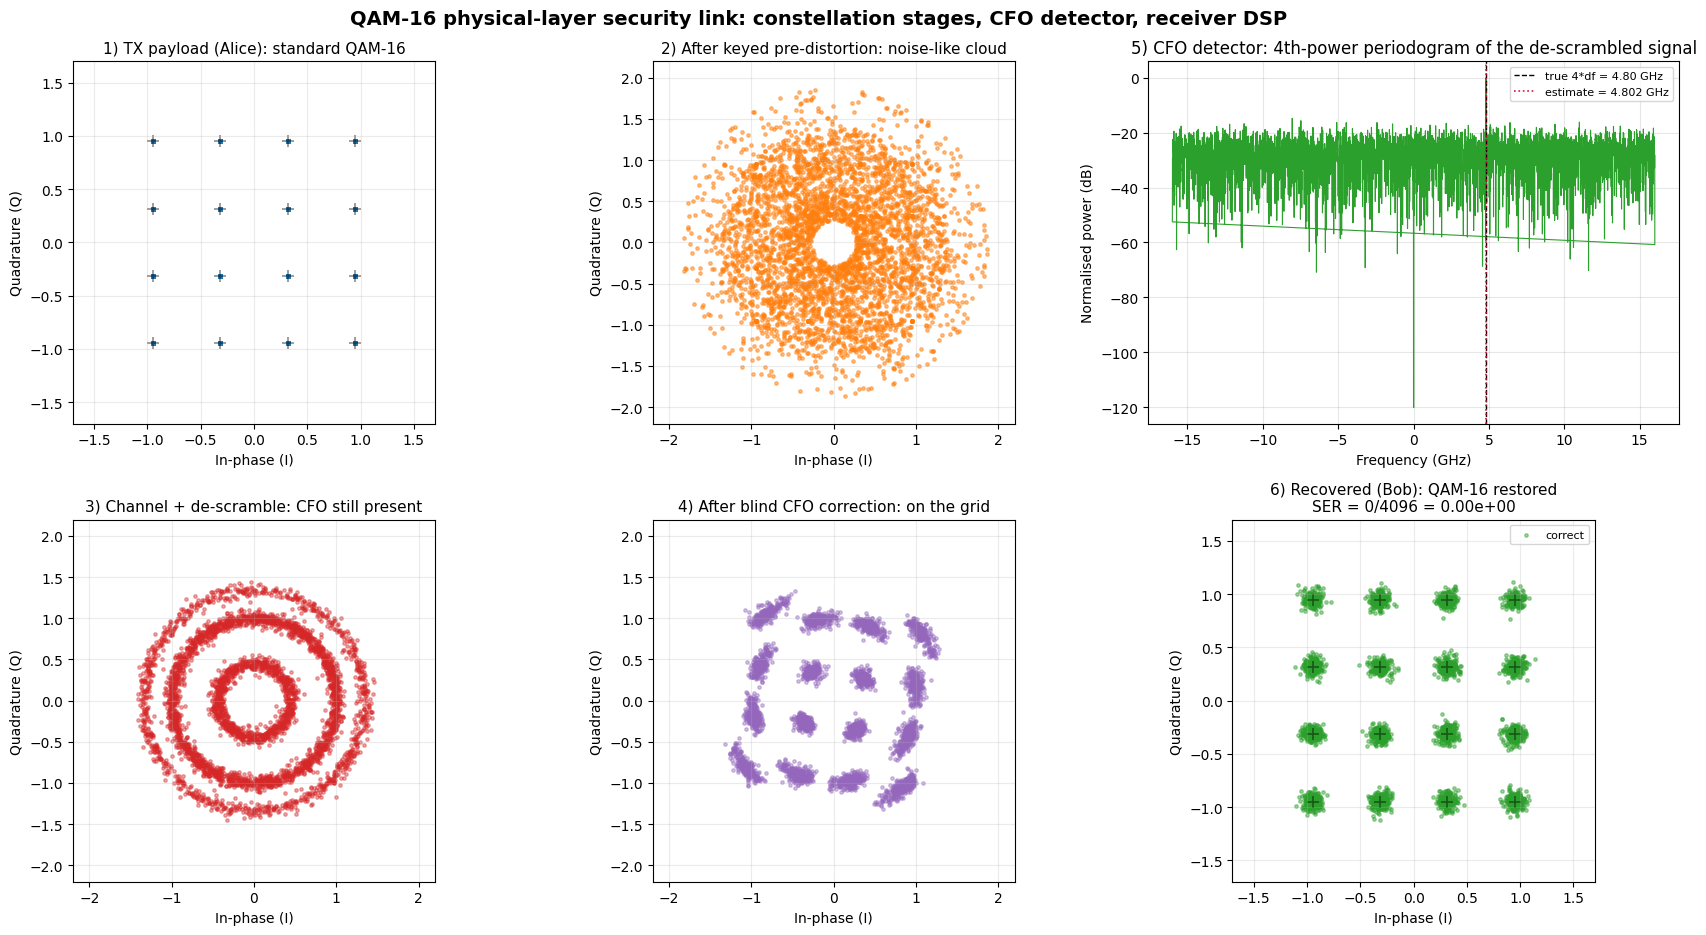

In [ ]:
# ----------------------------------------------------------------------
# VISUALIZATION: QAM-16 constellation through the link, with the CFO detector
# Requires the link cell above to have been executed.
# ----------------------------------------------------------------------
import matplotlib.pyplot as plt

link_stages = link                      # produced by the link cell
rx_rec = link_stages['recovered']
sliced = slice_qam16(rx_rec)
err_mask = np.abs(sliced - tx_payload) > 1e-6

def style_constellation(ax, title, show_grid=True, lim=1.7):
    if show_grid:
        ax.plot(QAM16_IDEAL.real, QAM16_IDEAL.imag, 'k+', ms=9, mew=1.2, alpha=0.45, zorder=1)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, alpha=0.25)

fig, axs = plt.subplots(2, 3, figsize=(17.5, 9.5))
fig.suptitle("QAM-16 physical-layer security link: constellation stages, CFO detector, receiver DSP",
             fontsize=14, fontweight='bold')

# 1) Transmitter payload
axs[0, 0].scatter(tx_payload.real, tx_payload.imag, s=6, c='tab:blue', alpha=0.5)
style_constellation(axs[0, 0], "1) TX payload (Alice): standard QAM-16")

# 2) After keyed pre-distortion
axs[0, 1].scatter(tx_scrambled.real, tx_scrambled.imag, s=6, c='tab:orange', alpha=0.5)
style_constellation(axs[0, 1], "2) After keyed pre-distortion: noise-like cloud",
                    show_grid=False, lim=2.2)

# 3) After the channel and de-scrambling, still frequency-rotated
axs[1, 0].scatter(link_stages['descrambled'].real, link_stages['descrambled'].imag,
                  s=6, c='tab:red', alpha=0.4)
style_constellation(axs[1, 0], "3) Channel + de-scramble: CFO still present",
                    show_grid=False, lim=2.2)

# 4) After blind CFO correction
axs[1, 1].scatter(link_stages['cfo_corrected'].real, link_stages['cfo_corrected'].imag,
                  s=6, c='tab:purple', alpha=0.4)
style_constellation(axs[1, 1], "4) After blind CFO correction: on the grid",
                    show_grid=False, lim=2.2)

# 5) The detector itself
freqs, spec = cfo_spectrum(link_stages['descrambled'], SYMBOL_RATE_HZ)
axs[0, 2].plot(freqs / 1e9, 10 * np.log10(np.maximum(spec / spec.max(), 1e-12)), lw=0.8,
               color='tab:green')
axs[0, 2].axvline(4 * TRUE_CFO_HZ / 1e9, color='k', ls='--', lw=1,
                  label=f"true 4*df = {4*TRUE_CFO_HZ/1e9:.2f} GHz")
axs[0, 2].axvline(4 * link_stages['cfo_hat_hz'] / 1e9, color='crimson', ls=':', lw=1.2,
                  label=f"estimate = {4*link_stages['cfo_hat_hz']/1e9:.3f} GHz")
axs[0, 2].set_title("5) CFO detector: 4th-power periodogram of the de-scrambled signal")
axs[0, 2].set_xlabel("Frequency (GHz)")
axs[0, 2].set_ylabel("Normalised power (dB)")
axs[0, 2].legend(fontsize=8)
axs[0, 2].grid(True, alpha=0.3)

# 6) Recovered at the receiver
ok = ~err_mask
axs[1, 2].scatter(rx_rec[ok].real, rx_rec[ok].imag, s=6, c='tab:green', alpha=0.45, label="correct")
if err_mask.any():
    axs[1, 2].scatter(rx_rec[err_mask].real, rx_rec[err_mask].imag, s=22, c='red',
                      marker='x', label="error")
style_constellation(axs[1, 2], "6) Recovered (Bob): QAM-16 restored\n"
                               f"SER = {err_mask.sum()}/{len(tx_payload)} = {err_mask.mean():.2e}")
axs[1, 2].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


Comb line powers   : measured LLE spectrum (2-soliton crystal)
Usable lines       : 14 of 64 clear the 19 dB OSNR threshold at 25 dB on the strongest line (their spread is 5.4 dB)
Hop dwell          : 128 symbols = 4.0 ns (hardware: 1-100 us = 32k-3.2M symbols)
Frame              : 8192 payload symbols, 66 dwells, 5 round(s) over the comb
Dummy traffic      : on - idle lines carry full power (18.1 dB more total power, or the same power spread over more lines)



seed 0: Bob SER 9.644e-03 | Bob BER 2.411e-03 | Eve line ID   9.1%
seed 1: Bob SER 9.766e-03 | Bob BER 2.441e-03 | Eve line ID   4.5%
seed 2: Bob SER 9.155e-03 | Bob BER 2.289e-03 | Eve line ID   7.6%
Bob, strongest third of lines : SER 9.240e-03
Bob, weakest usable lines     : SER 1.015e-02
Bob overall                   : SER 9.521e-03 -> PASS (BER 2.41e-03 <= 2e-02)

Wideband Eve (no dummy traffic, so she is on the right line every time):
  line identification      : 100.0%
  naive QAM-16 slicing     : SER 0.877
  MAP on |y| (power class) : 0.777 correct vs 0.500 trivial baseline
  information leak         : 0.607 bits/symbol of 4 (15%)
  best-guess symbol SER    : 0.857 (chance 0.9375)

Dummy traffic (A/B) - energy-detector hit rate on the occupied line:
  no dummy : 100.0% correct line identifications
  dummy on : 9.1% correct line identifications (chance 7.1%)

Known-plaintext attack, mask learned on one frame and applied to the next:
  legacy  (mask reused across frames): payload

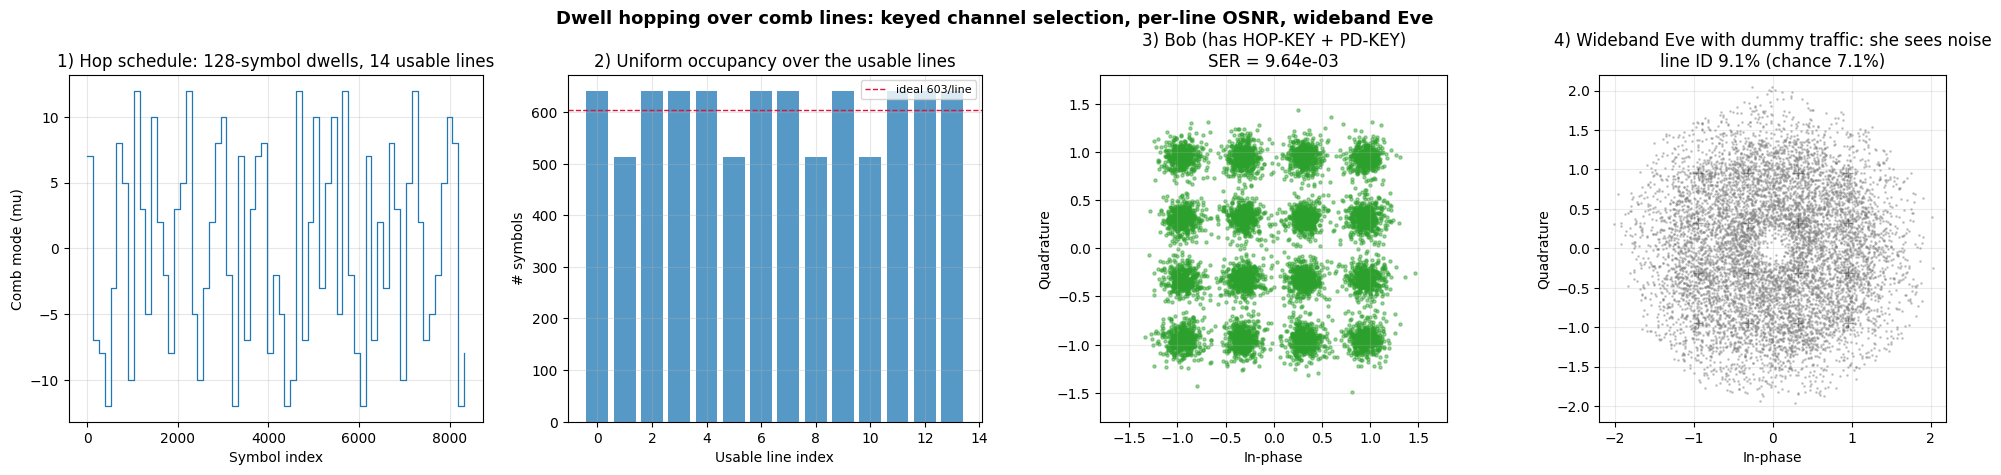

In [ ]:
# ======================================================================
# 5. TIME-HOPPING LAYER: dwell hopping over the usable comb lines
# ----------------------------------------------------------------------
# Each *dwell* of consecutive symbols is sent on one comb line chosen by the hop
# key, so both ends derive the schedule and the receiver de-hops for free.  A
# dwell of HOP_DWELL_SYMBOLS at 32 GBd is nanoseconds; real hardware hops in
# dwells of 1-100 us (32k-3.2M symbols), which needs frames of ~10^6 symbols.
#
# Per-line power now comes from the comb cell above (measured LLE spectrum), so
# off-centre lines are weaker exactly as a soliton sech^2 envelope makes them,
# instead of the flat "all lines equal" assumption used before.
#
# Stated assumption: Bob's coherent front end follows the hop schedule (a comb-
# matched receiver bank, or a tunable LO plus guard intervals).  That cost is not
# simulated.  The eavesdropper is NOT limited this way: she is given a wideband
# coherent receiver across the whole comb.
# ======================================================================
import numpy as np
import matplotlib.pyplot as plt

ROOT_SECRET = b"authenticated_puf_qrng_root_001"
N_COMB_ASSUMED = 64
HOP_DWELL_SYMBOLS = 128
N_BLOCKS = 8
TOTAL_SYMBOLS = N_BLOCKS * BLOCK_SIZE
FRAME_ID = 7
OSNR_REF_DB = 25.0          # OSNR of the strongest comb line, in 0.1 nm
OSNR_THRESHOLD_DB = 19.0    # 16-QAM crosses the 2e-2 BER threshold near here
DUMMY_TRAFFIC = True
N_SEEDS = 3

engine = HybridKeyEngine(ROOT_SECRET)
pd_key = engine.derive_key("PD-KEY")
hop_key = engine.derive_key("HOP-KEY")
rng = np.random.default_rng(7)   # payload draws only; keys never come from numpy
amplitudes = np.array([np.sqrt(2), np.sqrt(10), np.sqrt(18)]) / np.sqrt(10)
class_counts = np.array([4, 8, 4])
class_priors = class_counts / 16.0

# --- per-line power: measured LLE spectrum if the comb cell ran, else sech^2 ---
def soliton_envelope_db(mode_index, edge_mode, edge_drop_db=20.0):
    """Single-soliton (sech^2) envelope in dB, peak at mode 0.

    ``edge_mode`` is the mode number at which the envelope has dropped by
    ``edge_drop_db``; for a sech^2 spectrum that fixes the soliton bandwidth.
    """
    scale = edge_mode / np.arccosh(10.0 ** (edge_drop_db / 20.0))
    return -20.0 * np.log10(np.cosh(mode_index / scale))

if 'comb_line_power_db' in globals():
    line_power_full = np.asarray(comb_line_power_db, dtype=float)
    mode_index = np.asarray(comb_mode_index, dtype=float)
    power_source = f"measured LLE spectrum ({comb_state})"
else:
    mode_index = np.arange(N_COMB_ASSUMED, dtype=float) - (N_COMB_ASSUMED - 1) / 2.0
    line_power_full = soliton_envelope_db(mode_index, 12.0)
    power_source = "analytic sech^2 envelope (comb cell not run)"

# a line is usable only if its OSNR still clears the FEC threshold
line_power_full = np.minimum(line_power_full, 0.0)
usable = np.flatnonzero(line_power_full >= (OSNR_THRESHOLD_DB - OSNR_REF_DB))
line_power_db = line_power_full[usable]
line_gain = 10 ** (line_power_db / 20.0)      # per-line field gain (public calibration)
N_COMB = usable.size

# --- payload, transmit stream and hop schedule ---
tx_payload = generate_qam16_symbols(TOTAL_SYMBOLS, rng)
tx_stream = apply_pre_distortion(tx_payload, pd_key, FRAME_ID, BLOCK_SIZE)
n_blocks = TOTAL_SYMBOLS // BLOCK_SIZE
n_dwells = len(tx_stream) // HOP_DWELL_SYMBOLS
n_rounds = int(np.ceil(n_dwells / N_COMB))

def hop_line_per_sample(key, frame_id, n_dwells, usable_lines, n_rounds, dwell):
    """Keyed dwell schedule; every round visits each usable line exactly once."""
    line_idx = np.empty(min(n_dwells, n_rounds * usable_lines.size), dtype=np.int64)
    for r in range(n_rounds):
        order = np.argsort(keystream_uniforms(key, frame_id, r, usable_lines.size, label=b"HOP"),
                           kind='stable')
        for k in range(usable_lines.size):
            d = r * usable_lines.size + k
            if d < line_idx.size:
                line_idx[d] = usable_lines[order[k]]
    return np.repeat(line_idx, dwell)

hop_lines = hop_line_per_sample(hop_key, FRAME_ID, n_dwells, usable, n_rounds, HOP_DWELL_SYMBOLS)
hop_dwell_line = hop_lines[::HOP_DWELL_SYMBOLS]
payload_slots = payload_sample_mask(n_blocks, BLOCK_SIZE)
slot_sample_idx = np.flatnonzero(payload_slots)
slot_payload_idx = payload_index_at_time(pd_key, FRAME_ID, TOTAL_SYMBOLS, BLOCK_SIZE)[payload_slots]

def build_dummy_matrix(rng_like, n_lines, n):
    """Independent keyed dummy streams with the same statistics as the data."""
    rows = []
    for i in range(n_lines):
        p = generate_qam16_symbols(TOTAL_SYMBOLS, rng_like)
        rows.append(apply_pre_distortion(p, pd_key, FRAME_ID + 1000 + i, BLOCK_SIZE))
    return np.stack(rows)

def run_hop_link(seed, osnr_ref_db=OSNR_REF_DB, dummy=DUMMY_TRAFFIC, frame_id=FRAME_ID):
    """One end-to-end run: Bob with the keys, plus a wideband eavesdropper."""
    rng = np.random.default_rng(seed)
    n = len(tx_stream)

    sigma_phase = np.sqrt(2 * np.pi * 50e3 / SYMBOL_RATE_HZ)
    common_phase = np.exp(1j * np.cumsum(rng.normal(0.0, sigma_phase, n)))
    signal = tx_stream * common_phase

    ref_esn0 = osnr_db_to_esn0_db(osnr_ref_db)
    sig_power = float(np.mean(np.abs(tx_stream) ** 2))
    sigma = np.sqrt(sig_power / (2 * 10 ** (ref_esn0 / 10.0)))   # same ASE floor on every line
    noise = sigma * (rng.normal(size=(N_COMB, n)) + 1j * rng.normal(size=(N_COMB, n)))

    line_of_comb = np.searchsorted(usable, hop_lines)
    occupied = np.zeros((N_COMB, n), dtype=np.complex128)
    occupied[line_of_comb, np.arange(n)] = signal * line_gain[line_of_comb]
    if dummy:
        idle = occupied == 0.0
        gain_grid = np.repeat(line_gain[:, None], n, axis=1)
        occupied = np.where(idle, build_dummy_matrix(rng, N_COMB, n) * gain_grid, occupied)
    comb_rx = occupied + noise

    # ---- Bob: front end parked on the scheduled line ----
    # the comb envelope is static and public, so both ends hold a per-line
    # calibration table (not key material) and divide it out.
    bob_rx = comb_rx[line_of_comb, np.arange(n)] / line_gain[line_of_comb]
    bob_link = decode_frame(bob_rx, pd_key, frame_id, BLOCK_SIZE, SYMBOL_RATE_HZ)
    bob_stats = error_stats(tx_payload, bob_link['recovered'])
    err_by_symbol = np.abs(slice_qam16(bob_link['recovered']) - tx_payload) > 1e-6
    power_per_symbol = line_power_full[hop_lines[slot_sample_idx]]
    lo = power_per_symbol < line_power_db.max() - 3.0
    high_stats = error_stats(tx_payload[~lo], bob_link['recovered'][~lo])
    low_stats = error_stats(tx_payload[lo], bob_link['recovered'][lo])

    # ---- Eve: wideband receiver across the whole comb ----
    view = comb_rx[:, :hop_dwell_line.size * HOP_DWELL_SYMBOLS].reshape(
        N_COMB, hop_dwell_line.size, HOP_DWELL_SYMBOLS)
    # she knows her own noise floor, so she normalises each line before comparing
    noise_floor = np.median(np.mean(np.abs(view) ** 2, axis=2), axis=1)[:, None]
    eve_line = np.argmax(np.mean(np.abs(view) ** 2, axis=2) / noise_floor, axis=0)
    eve_correct = float(np.mean(eve_line == np.searchsorted(usable, hop_dwell_line)))

    eve_rx = comb_rx[np.repeat(eve_line, HOP_DWELL_SYMBOLS), np.arange(eve_line.size * HOP_DWELL_SYMBOLS)]
    eve_rx = eve_rx / line_gain[np.repeat(eve_line, HOP_DWELL_SYMBOLS)]
    eve_sym = eve_rx[slot_sample_idx]
    true_sym = tx_payload[slot_payload_idx]

    # attack 1: slice the scrambled samples as if they were plain QAM-16
    ser_naive = float(np.mean(np.abs(slice_qam16(eve_sym) - true_sym) > 1e-6))

    # attack 2: MAP estimate of the payload power class, then guess inside it
    mag = np.abs(eve_sym)
    dens = np.empty((mag.size, 3))
    for k, a in enumerate(amplitudes):
        lo, hi = SCRAMBLE_MIN_AMP * a, SCRAMBLE_MAX_AMP * a
        dens[:, k] = np.where((mag >= lo) & (mag <= hi),
                              1.0 / ((SCRAMBLE_MAX_AMP - SCRAMBLE_MIN_AMP) * a), 0.0)
    joint = dens * class_priors
    cls_hat = np.argmax(joint, axis=1)
    cls_true = np.argmin(np.abs(np.abs(true_sym)[None, :] - amplitudes[:, None]), axis=0)
    cls_acc = float(np.mean(cls_hat == cls_true))

    # empirical mutual information between the true class and her decision
    confusion = np.zeros((3, 3))
    for k in range(3):
        for kh in range(3):
            confusion[k, kh] = np.sum((cls_true == k) & (cls_hat == kh))
    confusion /= confusion.sum()
    py = confusion.sum(axis=0)
    mi_bits = 0.0
    for k in range(3):
        for kh in range(3):
            if confusion[k, kh] > 0:
                mi_bits += confusion[k, kh] * np.log2(confusion[k, kh] / (class_priors[k] * py[kh]))

    # her best symbol guess: MAP class, uniform choice inside that class
    points_by_class = [np.flatnonzero(np.isclose(np.abs(QAM16_IDEAL), a, atol=1e-6))
                       for a in amplitudes]
    pick = np.array([points_by_class[cls_hat[i]][rng.integers(0, class_counts[cls_hat[i]])]
                     for i in range(eve_sym.size)])
    ser_best = float(np.mean(np.abs(QAM16_IDEAL[pick] - true_sym) > 1e-6))

    return dict(bob_stats=bob_stats, bob_rec=bob_link['recovered'], cfo_hz=bob_link['cfo_hat_hz'],
                high_stats=high_stats, low_stats=low_stats, err_by_symbol=err_by_symbol,
                eve_correct=eve_correct, ser_naive=ser_naive, ser_best=ser_best,
                cls_acc=cls_acc, cls_baseline=float(class_priors.max()),
                mi_bits=float(mi_bits), eve_line=eve_line, line_of_comb=line_of_comb,
                comb_rx=comb_rx)

def mask_reuse_attack(static_mask=True, known_frame=FRAME_ID):
    """Known-plaintext attack: learn the mask on one frame, apply it to the next.

    With a per-frame nonce the mask of the next frame is independent, so the
    learned mask is useless; with a static mask the attack recovers everything.
    """
    frame_a = known_frame if static_mask else known_frame
    frame_b = known_frame if static_mask else known_frame + 1
    tx_a = apply_pre_distortion(tx_payload, pd_key, frame_a, BLOCK_SIZE)
    tx_b = apply_pre_distortion(tx_payload, pd_key, frame_b, BLOCK_SIZE)
    mask_slot = tx_a[slot_sample_idx] / tx_payload[slot_payload_idx]   # from known plaintext
    recovered = np.empty(TOTAL_SYMBOLS, dtype=np.complex128)
    recovered[slot_payload_idx] = tx_b[slot_sample_idx] / mask_slot
    return float(np.mean(np.abs(slice_qam16(recovered) - tx_payload) > 1e-6))

# ----------------------------------------------------------------------
# RESULTS
# ----------------------------------------------------------------------
print(f"Comb line powers   : {power_source}")
print(f"Usable lines       : {N_COMB} of {N_COMB_ASSUMED} clear the {OSNR_THRESHOLD_DB:.0f} dB OSNR "
      f"threshold at {OSNR_REF_DB:.0f} dB on the strongest line "
      f"(their spread is {line_power_db.max()-line_power_db.min():.1f} dB)")
print(f"Hop dwell          : {HOP_DWELL_SYMBOLS} symbols = "
      f"{HOP_DWELL_SYMBOLS/SYMBOL_RATE_HZ*1e9:.1f} ns (hardware: 1-100 us = 32k-3.2M symbols)")
print(f"Frame              : {TOTAL_SYMBOLS} payload symbols, {hop_dwell_line.size} dwells, "
      f"{n_rounds} round(s) over the comb")
print(f"Dummy traffic      : {'on' if DUMMY_TRAFFIC else 'off'} - idle lines carry full power "
      f"({'%.1f' % (10*np.log10(N_COMB_ASSUMED))} dB more total power, or the same power spread "
      f"over more lines)")
print()
results = [run_hop_link(seed) for seed in range(N_SEEDS)]
for seed, r in enumerate(results):
    print(f"seed {seed}: Bob SER {r['bob_stats']['ser']:.3e} | Bob BER "
          f"{r['bob_stats']['ber_est']:.3e} | Eve line ID {r['eve_correct']*100:5.1f}%")
print(f"Bob, strongest third of lines : SER {np.mean([r['high_stats']['ser'] for r in results]):.3e}")
print(f"Bob, weakest usable lines     : SER {np.mean([r['low_stats']['ser'] for r in results]):.3e}")
print(f"Bob overall                   : SER {np.mean([r['bob_stats']['ser'] for r in results]):.3e} "
      f"-> {fec_verdict(results[0]['bob_stats'])}")

# A wideband eavesdropper sees every symbol, so the hop layer alone does not hide
# anything from her.  Measure what she can do with a scrambled stream instead.
r_clean = run_hop_link(0, dummy=False)
print()
print("Wideband Eve (no dummy traffic, so she is on the right line every time):")
print(f"  line identification      : {100*r_clean['eve_correct']:.1f}%")
print(f"  naive QAM-16 slicing     : SER {r_clean['ser_naive']:.3f}")
print(f"  MAP on |y| (power class) : {r_clean['cls_acc']:.3f} correct vs "
      f"{r_clean['cls_baseline']:.3f} trivial baseline")
print(f"  information leak         : {r_clean['mi_bits']:.3f} bits/symbol of 4 "
      f"({100*r_clean['mi_bits']/4:.0f}%)")
print(f"  best-guess symbol SER    : {r_clean['ser_best']:.3f} (chance 0.9375)")
print()
print("Dummy traffic (A/B) - energy-detector hit rate on the occupied line:")
print(f"  no dummy : {100*r_clean['eve_correct']:.1f}% correct line identifications")
print(f"  dummy on : {100*results[0]['eve_correct']:.1f}% correct line identifications "
      f"(chance {100.0/N_COMB:.1f}%)")

print()
print("Known-plaintext attack, mask learned on one frame and applied to the next:")
print(f"  legacy  (mask reused across frames): payload SER "
      f"{mask_reuse_attack(static_mask=True):.4f}  <- frame 1 unmasks every later frame")
print(f"  fixed   (per-frame nonce)          : payload SER "
      f"{mask_reuse_attack(static_mask=False):.4f}  (chance 0.9375)")

# ----------------------------------------------------------------------
# PLOTS
# ----------------------------------------------------------------------
r0 = results[0]
fig, axs = plt.subplots(1, 4, figsize=(20, 4.8))
fig.suptitle("Dwell hopping over comb lines: keyed channel selection, per-line OSNR, wideband Eve",
             fontsize=13, fontweight='bold')

axs[0].step(np.arange(hop_dwell_line.size) * HOP_DWELL_SYMBOLS, mode_index[hop_dwell_line],
            where='post', color='tab:blue', lw=0.9)
axs[0].set_title(f"1) Hop schedule: {HOP_DWELL_SYMBOLS}-symbol dwells, "
                 f"{N_COMB} usable lines")
axs[0].set_xlabel("Symbol index"); axs[0].set_ylabel("Comb mode (mu)")
axs[0].grid(True, alpha=0.3)

counts = np.bincount(r0['line_of_comb'], minlength=N_COMB)
axs[1].bar(np.arange(N_COMB), counts, color='tab:blue', alpha=0.75)
axs[1].axhline(len(hop_lines) / N_COMB, color='crimson', ls='--', lw=1,
               label=f"ideal {len(hop_lines)/N_COMB:.0f}/line")
axs[1].set_title("2) Uniform occupancy over the usable lines")
axs[1].set_xlabel("Usable line index"); axs[1].set_ylabel("# symbols")
axs[1].legend(fontsize=8); axs[1].grid(True, alpha=0.3)

axs[2].plot(QAM16_IDEAL.real, QAM16_IDEAL.imag, 'k+', ms=9, mew=1.2, alpha=0.45, zorder=1)
axs[2].scatter(r0['bob_rec'].real, r0['bob_rec'].imag, s=5, c='tab:green', alpha=0.45)
axs[2].set_title(f"3) Bob (has HOP-KEY + PD-KEY)\nSER = {r0['bob_stats']['ser']:.2e}")
axs[2].set_xlabel("In-phase"); axs[2].set_ylabel("Quadrature")
axs[2].set_xlim(-1.8, 1.8); axs[2].set_ylim(-1.8, 1.8)
axs[2].set_aspect('equal', adjustable='box'); axs[2].grid(True, alpha=0.25)

eve_samples = r0['comb_rx'][np.repeat(r0['eve_line'], HOP_DWELL_SYMBOLS),
                            np.arange(r0['eve_line'].size * HOP_DWELL_SYMBOLS)]
eve_samples = eve_samples / line_gain[np.repeat(r0['eve_line'], HOP_DWELL_SYMBOLS)]
axs[3].plot(eve_samples.real, eve_samples.imag, '.', ms=2, alpha=0.35, color='grey')
axs[3].plot(QAM16_IDEAL.real, QAM16_IDEAL.imag, 'k+', ms=7, mew=1.0, alpha=0.35)
axs[3].set_title(f"4) Wideband Eve with dummy traffic: she sees noise\n"
                 f"line ID {r0['eve_correct']*100:.1f}% (chance {100/N_COMB:.1f}%)")
axs[3].set_xlabel("In-phase"); axs[3].set_ylabel("Quadrature")
axs[3].set_xlim(-2.2, 2.2); axs[3].set_ylim(-2.2, 2.2)
axs[3].set_aspect('equal', adjustable='box'); axs[3].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


Sweep              : 8 OSNR points x 2 seeds x 16384 symbols = 262144 symbols per curve
Resolution floor   : BER 2.29e-05 (95% bound when no error is seen)

OSNR (dB)  BER, mask on  BER, mask off   max CFO error
     12.0     1.061e-01      9.954e-02        0.106 MHz
     14.0     7.291e-02      6.393e-02        0.106 MHz
     16.0     4.211e-02      3.141e-02        0.106 MHz
     18.0     2.069e-02      1.114e-02        0.106 MHz
     20.0     7.790e-03      2.266e-03        0.106 MHz
     22.0     2.144e-03      1.678e-04        0.106 MHz
     24.0     3.967e-04      7.629e-06        0.106 MHz
     26.0     3.052e-05       <2.3e-05        0.137 MHz

OSNR at BER = 2e-02  mask on  : 18.07 dB
OSNR at BER = 2e-02  mask off : 16.87 dB
Measured amplitude-mask penalty : 1.20 dB   (analytic: 0.98 dB)
Analytic for reference: 0.76 dB noise enhancement, PAPR 5.25 dB (+2.70 dB)


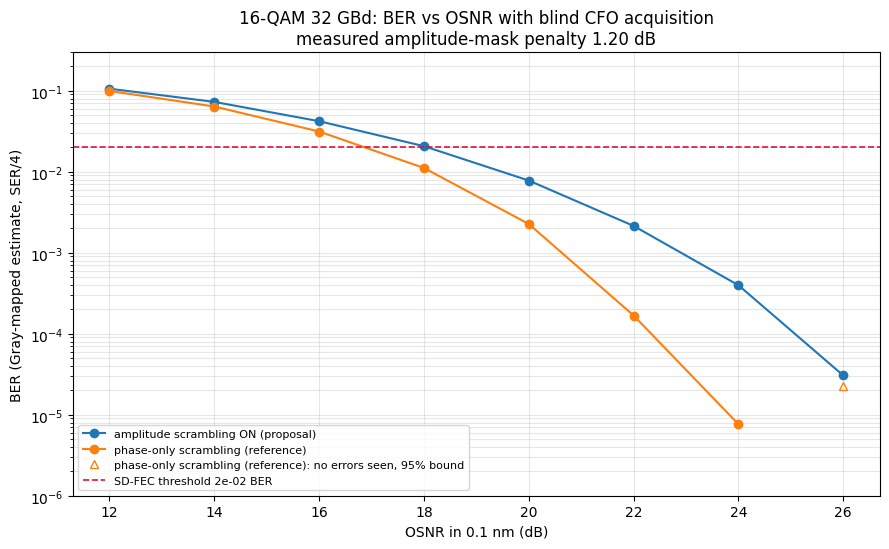

In [ ]:
# ======================================================================
# 6. BER vs OSNR waterfall, and the measured cost of the amplitude mask
# ----------------------------------------------------------------------
# This is the curve the original notebook never produced: a BER-vs-OSNR sweep
# against a stated SD-FEC threshold, plus the SNR penalty that the amplitude
# scrambling costs.  Two configurations are swept:
#     amplitude scrambling ON  (the security proposal)
#     amplitude scrambling OFF (phase-only scrambling: reference)
# so the horizontal shift between the curves *is* the amplitude-mask penalty.
#
# Resolution floor: with N_SWEEP symbols and zero observed errors the 95% upper
# bound on the BER is (3/N_SWEEP)/4.  Points with no error are therefore drawn as
# open triangles at that bound, not as "zero BER".
# ======================================================================
import matplotlib.pyplot as plt

OSNR_SWEEP_DB = np.arange(12.0, 26.1, 2.0)
N_SWEEP = 16384
SWEEP_SEEDS = (1, 2)
SWEEP_FRAME_ID = 100

def sweep_point(osnr_db, seed, scramble_amplitude=True, n_symbols=N_SWEEP):
    """One BER/OSNR measurement, with an unknown random CFO and no side info."""
    rng = np.random.default_rng(seed)
    frame_id = SWEEP_FRAME_ID + seed
    payload = generate_qam16_symbols(n_symbols, rng)
    tx = apply_pre_distortion(payload, pd_key, frame_id, BLOCK_SIZE, scramble_amplitude)
    cfo_true_hz = rng.uniform(-3.0e9, 3.0e9)
    rx = optical_channel(tx, rng, SYMBOL_RATE_HZ, cfo_hz=cfo_true_hz, linewidth_hz=50e3,
                         esn0_db=osnr_db_to_esn0_db(osnr_db))
    out = decode_frame(rx, pd_key, frame_id, BLOCK_SIZE, SYMBOL_RATE_HZ,
                       scramble_amplitude=scramble_amplitude)
    sliced = slice_qam16(out['recovered'])
    errors = int(np.sum(np.abs(sliced - payload) > 1e-6))
    return errors, payload.size, abs(out['cfo_hat_hz'] - cfo_true_hz)

def cross_osnr(x, y, target=SD_FEC_BER):
    """OSNR at which the BER curve crosses `target` (log-BER linear in OSNR dB)."""
    for i in range(len(x) - 1):
        y0, y1 = y[i], y[i + 1]
        if y0 > target >= y1 and y0 > 0 and y1 > 0:
            frac = (np.log10(y0) - np.log10(target)) / (np.log10(y0) - np.log10(y1))
            return x[i] + frac * (x[i + 1] - x[i])
    return np.nan

sweep = {}
for scramble_amplitude in (True, False):
    ber_obs, ber_ub, cfo_err = [], [], []
    for osnr_db in OSNR_SWEEP_DB:
        errors, total, cerr = 0, 0, 0.0
        for seed in SWEEP_SEEDS:
            e, n, c = sweep_point(osnr_db, seed, scramble_amplitude)
            errors += e
            total += n
            cerr = max(cerr, c)
        ser = errors / total
        ber = ser / 4.0
        ber_obs.append(ber)
        ber_ub.append((3.0 / total) / 4.0)
        cfo_err.append(cerr)
    sweep[scramble_amplitude] = dict(ber=np.array(ber_obs), ber_ub=np.array(ber_ub),
                                     cfo_err=np.array(cfo_err))

curve_on, curve_off = sweep[True], sweep[False]
x_on = cross_osnr(OSNR_SWEEP_DB, curve_on['ber'])
x_off = cross_osnr(OSNR_SWEEP_DB, curve_off['ber'])
pen = scrambling_penalty()

print(f"Sweep              : {len(OSNR_SWEEP_DB)} OSNR points x {len(SWEEP_SEEDS)} seeds x "
      f"{N_SWEEP} symbols = {len(OSNR_SWEEP_DB)*len(SWEEP_SEEDS)*N_SWEEP} symbols per curve")
print(f"Resolution floor   : BER {curve_on['ber_ub'].min():.2e} (95% bound when no error is seen)")
print()
print(f"{'OSNR (dB)':>9} {'BER, mask on':>13} {'BER, mask off':>14}   {'max CFO error':>13}")
for i, osnr_db in enumerate(OSNR_SWEEP_DB):
    on = f"{curve_on['ber'][i]:.3e}" if curve_on['ber'][i] > 0 else f"<{curve_on['ber_ub'][i]:.1e}"
    off = f"{curve_off['ber'][i]:.3e}" if curve_off['ber'][i] > 0 else f"<{curve_off['ber_ub'][i]:.1e}"
    print(f"{osnr_db:9.1f} {on:>13} {off:>14}   {max(curve_on['cfo_err'][i], curve_off['cfo_err'][i])/1e6:10.3f} MHz")
print()
print(f"OSNR at BER = {SD_FEC_BER:.0e}  mask on  : {x_on:.2f} dB")
print(f"OSNR at BER = {SD_FEC_BER:.0e}  mask off : {x_off:.2f} dB")
print(f"Measured amplitude-mask penalty : {x_on - x_off:.2f} dB   "
      f"(analytic: {pen['net_penalty_db']:.2f} dB)")
print(f"Analytic for reference: {pen['noise_enhancement_db']:.2f} dB noise enhancement, "
      f"PAPR {pen['papr_db']:.2f} dB ({pen['papr_penalty_db']:+.2f} dB)")

fig, ax = plt.subplots(figsize=(9, 5.6))
for key, label, colour in ((True, "amplitude scrambling ON (proposal)", 'tab:blue'),
                           (False, "phase-only scrambling (reference)", 'tab:orange')):
    c = sweep[key]
    seen = c['ber'] > 0
    ax.semilogy(OSNR_SWEEP_DB[seen], np.maximum(c['ber'][seen], 1e-6), 'o-', color=colour, label=label)
    if (~seen).any():
        ax.semilogy(OSNR_SWEEP_DB[~seen], c['ber_ub'][~seen], '^', mfc='none', color=colour,
                    label=f"{label}: no errors seen, 95% bound")
ax.axhline(SD_FEC_BER, color='crimson', ls='--', lw=1.2,
           label=f"SD-FEC threshold {SD_FEC_BER:.0e} BER")
ax.set_xlabel("OSNR in 0.1 nm (dB)")
ax.set_ylabel("BER (Gray-mapped estimate, SER/4)")
ax.set_title("16-QAM 32 GBd: BER vs OSNR with blind CFO acquisition\n"
             f"measured amplitude-mask penalty {x_on - x_off:.2f} dB")
ax.set_ylim(1e-6, 3e-1)
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()
